<a href="https://colab.research.google.com/github/isapour0/First-Repository/blob/main/CIFAR-10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="
background:linear-gradient(135deg,#171922,#10131b);
border:2px solid #3ce7e7;
border-radius:22px;
padding:32px;
font-family:-apple-system,BlinkMacSystemFont,'Segoe UI',Roboto,Arial,sans-serif;
color:white;
box-shadow:0 0 18px rgba(60,231,231,.18);
">

<div style="display:flex;align-items:center;gap:14px;">
<span style="font-size:34px;">👨‍💻</span>

<div>
<div style="
font-size:34px;
font-weight:800;
color:#4ff5f5;
text-shadow:0 0 8px rgba(79,245,245,.35);
">
Aliakbar Isapour
</div>

<div style="
color:#bfbfbf;
font-size:16px;
margin-top:3px;
">
Machine Learning • Data Science • AI
</div>
</div>
</div>

<div style="
height:2px;
background:linear-gradient(90deg,#7b3ff2,#4ff5f5);
border-radius:5px;
margin:22px 0;
"></div>

<div style="
color:#d7d7d7;
font-size:16px;
line-height:1.7;
margin-bottom:25px;
">

</div>


<div style="display:flex;gap:14px;flex-wrap:wrap;">

<a href="https://github.com/isapour0"
target="_blank"
rel="noopener noreferrer"
style="
display:inline-block;
margin: 0 10px;
text-decoration:none;
background:#23283a;
color:#4ff5f5;
padding:12px 22px;
border-radius:12px;
border:1px solid #4ff5f5;
font-weight:bold;
transition:0.25s;
">
GitHub
</a>

<a href="https://www.linkedin.com/in/aliakbar-isapour-682592413"
target="_blank"
rel="noopener noreferrer"
style="
display:inline-block;
margin: 0 10px;
text-decoration:none;
background:#23283a;
color:#4ff5f5;
padding:12px 22px;
border-radius:12px;
border:1px solid #4ff5f5;
font-weight:bold;
transition:0.25s;
">
LinkedIn
</a>


</div>

</div>

<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">📌 Library Imports</h2>
<hr style="border:1px solid #8A2BE2; opacity:.4;">

<ul>
<li></li>
</ul>

</div>


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
import os

from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam

<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-radius:18px;
border-left: 8px solid #00E5FF;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">
    
<h2 style="color:#00E5FF;">📂 Data Loding</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">

<ul>
<li></li>
</ul>

</div>


In [4]:
from google.colab import drive
drive.mount('/content/drive')

data_path = '/content/drive/MyDrive/CIFAR-10'
os.makedirs(data_path, exist_ok=True)

Mounted at /content/drive


In [5]:
X_train_path = f'{data_path}/X_train.npy'
y_train_path = f'{data_path}/y_train.npy'
X_test_path = f'{data_path}/X_test.npy'
y_test_path = f'{data_path}/y_test.npy'

if all(os.path.exists(path) for path in [X_train_path, y_train_path, X_test_path, y_test_path]):
  print ('Loading CIFAR-10 from google drive...')
  X_train = np.load(X_train_path)
  y_train = np.load(y_train_path)
  X_test = np.load(X_test_path)
  y_test = np.load(y_test_path)
else:
  print ('Downloading CIFAR-10 dataset...')
  (X_train, y_train), (X_test, y_test) = cifar10.load_data()
  np.save(X_train_path, X_train)
  np.save(y_train_path, y_train)
  np.save(X_test_path, X_test)
  np.save(y_test_path, y_test)
  print ('CIFAR-10 dataset downloaded and saved to google drive.')

Loading CIFAR-10 from google drive...


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">📊 EDA</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">

<ul>
<li></li>
</ul>
</div>

In [6]:
print ('X_train shape:', X_train.shape)
print ('y_train shape:', y_train.shape)
print ('X_test shape:', X_test.shape)
print ('y_test shape:', y_test.shape)

X_train shape: (50000, 32, 32, 3)
y_train shape: (50000, 1)
X_test shape: (10000, 32, 32, 3)
y_test shape: (10000, 1)


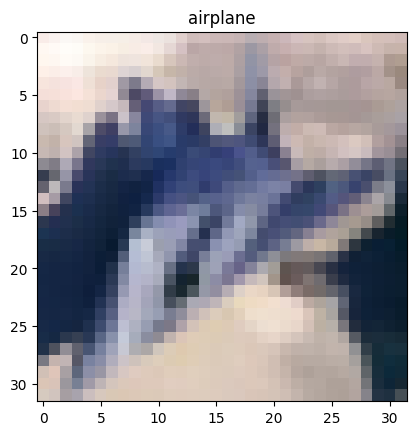

In [7]:
# Display a custom image
class_name = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
plt.imshow(X_train[555])
plt.title(class_name[int(y_train[555, 0])])
plt.show()

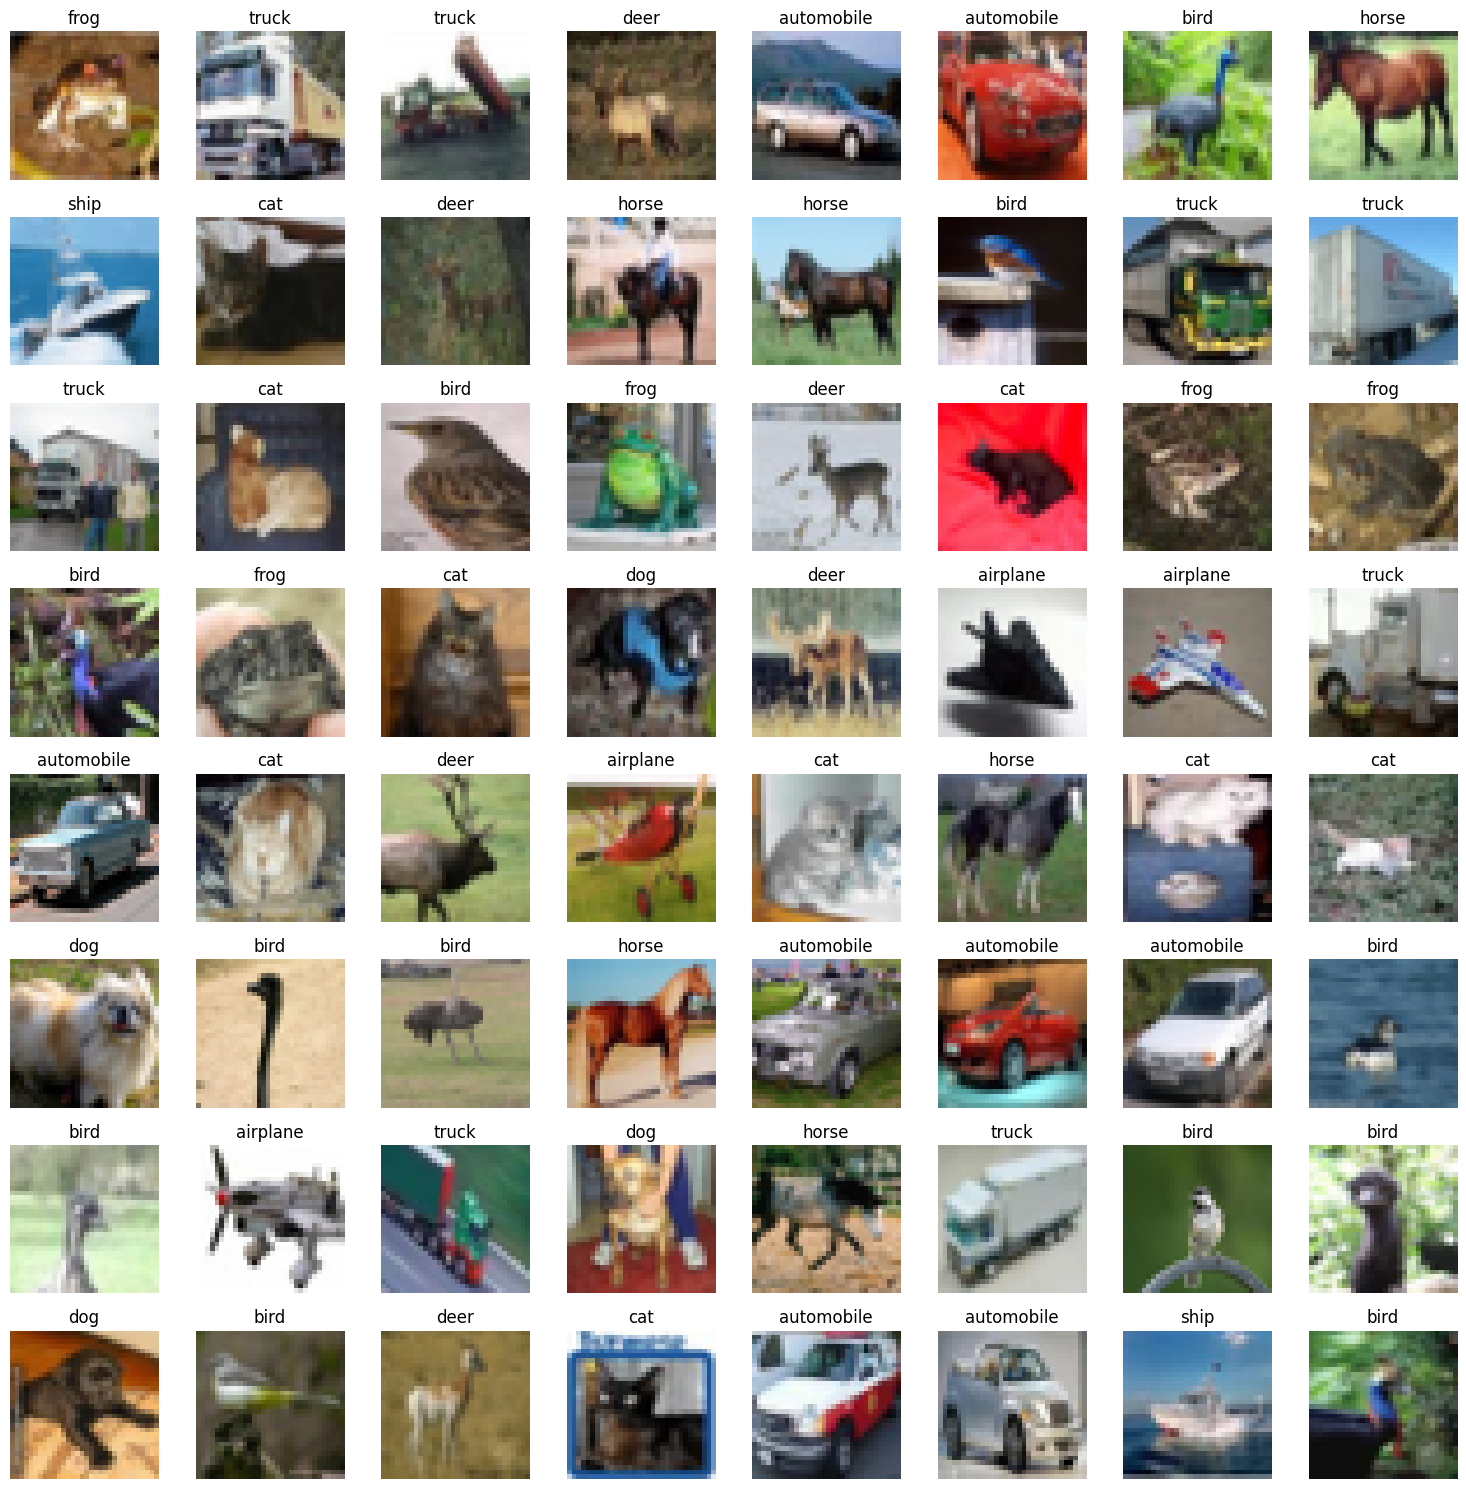

In [8]:
# Class name
class_name = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# set figure size and creating subplots
fig, axes = plt.subplots(8, 8, figsize=(15, 15))

# Loop over the first 64 images
for i, ax in enumerate(axes.ravel()):
  ax.imshow(X_train[i])
  ax.set_title(class_name[y_train[i][0]])
  ax.axis('off')

plt.tight_layout()
plt.show()

In [9]:
classes_name = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer', 'Dog', 'Frog', 'Horse', 'Ship', 'Truck']

Unique_train, counts_train = np.unique(y_train, return_counts=True)

for label, count in zip(Unique_train, counts_train):
  print (f'Class {classes_name[label]}: {count}')

Class Airplane: 5000
Class Automobile: 5000
Class Bird: 5000
Class Cat: 5000
Class Deer: 5000
Class Dog: 5000
Class Frog: 5000
Class Horse: 5000
Class Ship: 5000
Class Truck: 5000


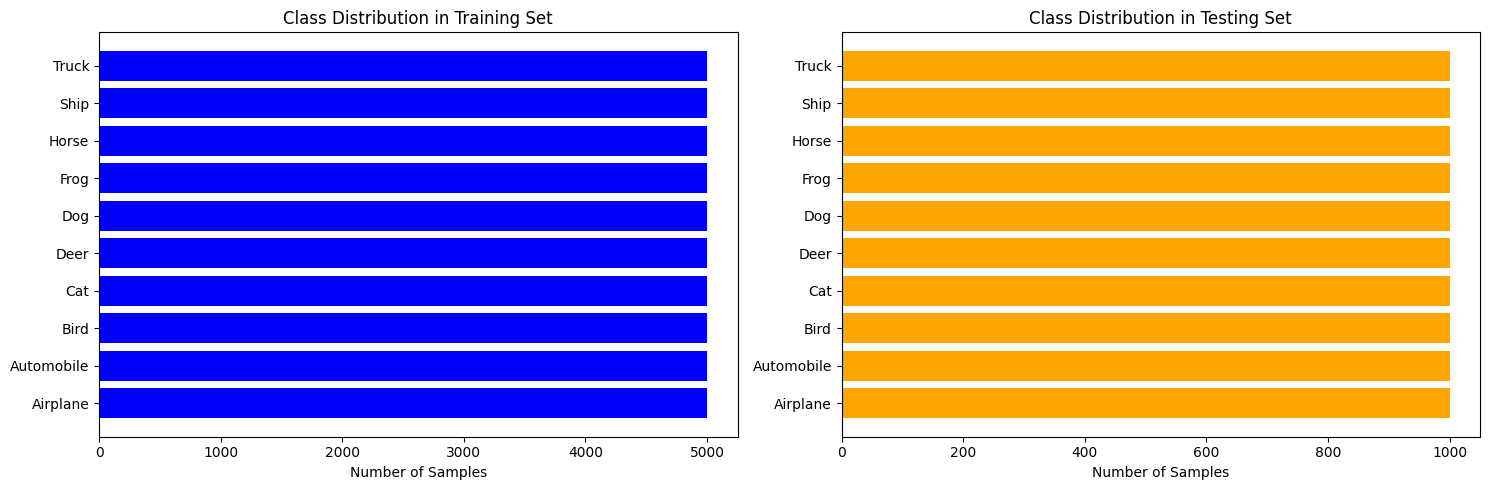

In [10]:
# Define class names
classes_name = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer', 'Dog', 'Frog', 'Horse', 'Ship', 'Truck']

# Class distribution for Training and testing data
Unique_train, counts_train = np.unique(y_train, return_counts=True)
Unique_test, counts_test = np.unique(y_test, return_counts=True)

# Set figure size and create subplots
plt.figure(figsize=(15, 5))

# Plot class distribution for training set
plt.subplot(1, 2, 1)
plt.barh(classes_name, counts_train, color='blue')
plt.xlabel('Number of Samples')
plt.title('Class Distribution in Training Set')

# Plot class distribution for testing set
plt.subplot(1, 2, 2)
plt.barh(classes_name, counts_test, color='orange')
plt.xlabel('Number of Samples')
plt.title('Class Distribution in Testing Set')

plt.tight_layout()
plt.show()

In [11]:
# Ckecking the range of data values
print ('Minumim :', X_train.min())
print ('Maximum: ', X_train.max())

Minumim : 0
Maximum:  255


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">🔧 Preprocessing</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">

<ul>
<li></li>
</ul>
</div>

In [12]:
# Normalizing data to the range of 0 to 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print (f'X_train_min: {X_train.min()}  X_train_max: {X_train.max()}')
print (f'X_test_min : {X_test.min()}  X_test_max:  {X_test.max()}')

print (f'y_train_min: {y_train.min()}    y_train_max: {y_train.max()}')
print (f'y_test_min : {y_test.min()}    y_test_max: {y_test.max()}')

X_train_min: 0.0  X_train_max: 1.0
X_test_min : 0.0  X_test_max:  1.0
y_train_min: 0    y_train_max: 9
y_test_min : 0    y_test_max: 9


In [13]:
# Flatten image
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

print ('X_train is reshape: ', X_train_flat.shape)
print ('X_test is reshape : ', X_test_flat.shape)

X_train is reshape:  (50000, 3072)
X_test is reshape :  (10000, 3072)


In [14]:

y_train = to_categorical(y_train, num_classes=10)
y_test = to_categorical(y_test, num_classes=10)

print ('y_train shape: ', y_train.shape)
print ('y_test shape : ', y_test.shape)

y_train shape:  (50000, 10)
y_test shape :  (10000, 10)


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">🤖 MLP Model</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">

<ul>
<li></li>
</ul>
</div>

In [23]:
# Building a basic MLP model
model = Sequential([
    Dense(256, activation='relu', input_shape=(3072,)),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(10, activation='softmax')

])

In [24]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 828,490 (3.16 MB)

 Trainable params: 828,490 (3.16 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
# compile the model

opitimizer = Adam(0.001)
model.compile(
    optimizer=opitimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)

In [27]:
# Training the model with dataset CIFAR-10
history = model.fit(
    X_train_flat, y_train,
    validation_split=0.1,
    epochs=100,
    batch_size=128,
    verbose=1
)

Epoch 1/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.2791 - loss: 1.9500 - val_accuracy: 0.3334 - val_loss: 1.8723
Epoch 2/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.3056 - loss: 1.8883 - val_accuracy: 0.3310 - val_loss: 1.8333
Epoch 3/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.3209 - loss: 1.8538 - val_accuracy: 0.3462 - val_loss: 1.7997
Epoch 4/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.3318 - loss: 1.8278 - val_accuracy: 0.3690 - val_loss: 1.7804
Epoch 5/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.3417 - loss: 1.8046 - val_accuracy: 0.3816 - val_loss: 1.7411
Epoch 6/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.3523 - loss: 1.7860 - val_accuracy: 0.3870 - val_loss: 1.7299
Epoch 7/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.3558 - loss: 1.7710 - val_accuracy: 0.4010 - val_loss: 1.6972
Epoch 8/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.3628 - loss: 1.7594 

In [28]:
# Accuracy and Error rate analysis
test_loss, test_accuracy = model.evaluate(X_test_flat, y_test, verbose=1)

print (f'test loss: {test_loss:.4f}')
print (f'test accuracy: {test_accuracy:.4f}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4648 - loss: 1.5028
test loss: 1.5028
test accuracy: 0.4648


In [29]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

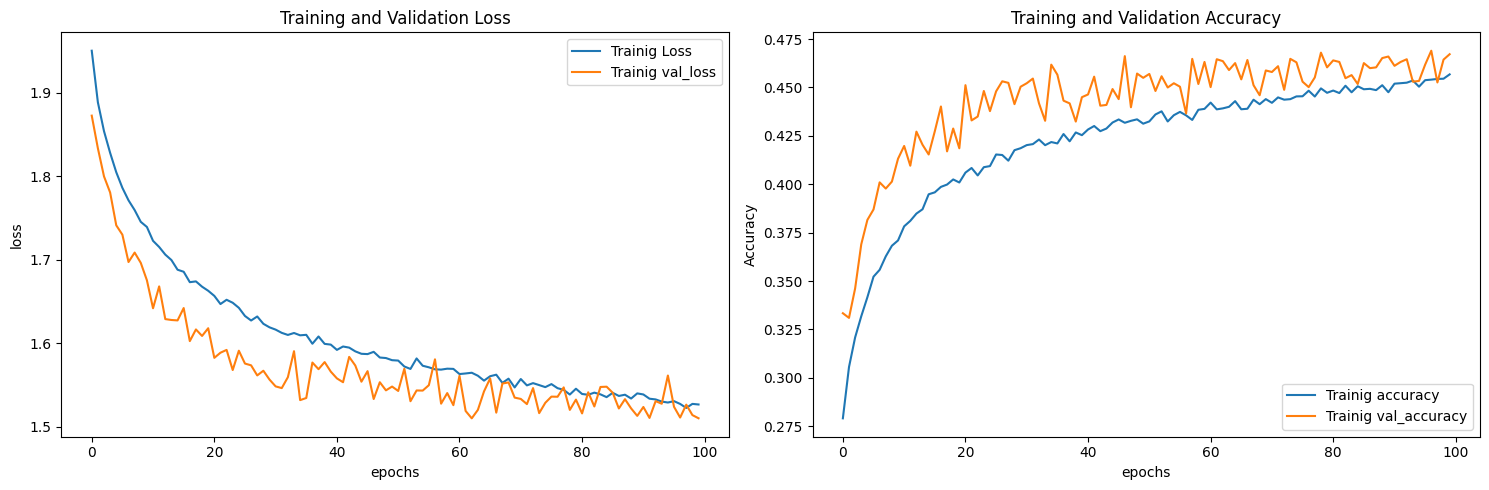

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(history.history['loss'], label='Trainig Loss')
axes[0].plot(history.history['val_loss'], label='Trainig val_loss')
axes[0].set_title('Training and Validation Loss')
axes[0].set_xlabel('epochs')
axes[0].set_ylabel('loss')
axes[0].legend()

axes[1].plot(history.history['accuracy'], label='Trainig accuracy')
axes[1].plot(history.history['val_accuracy'], label='Trainig val_accuracy')
axes[1].set_title('Training and Validation Accuracy')
axes[1].set_xlabel('epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

In [45]:
yhat = model.predict(X_test_flat)
yhat_classes = np.argmax(yhat, axis=1)

print (yhat.shape)
print (yhat_classes.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
(10000, 10)
(10000,)


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-radius:18px;
border-left: 8px solid #00E5FF;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">
<h2 style="color:#00E5FF;">Evaluation MLP model</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">
<ul>
<li></li>
</ul>
</div>

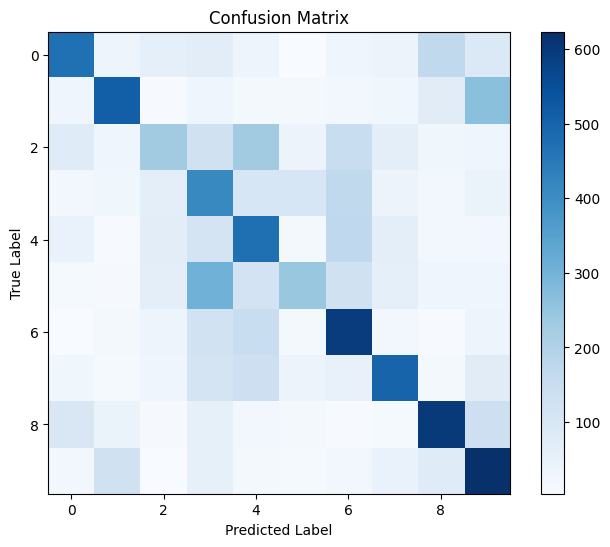

In [47]:
cm = confusion_matrix(y_test.argmax(axis=1), yhat_classes)

plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [50]:
print (classification_report(y_test.argmax(axis=1), yhat_classes))

              precision    recall  f1-score   support

           0       0.58      0.47      0.52      1000
           1       0.62      0.51      0.56      1000
           2       0.40      0.23      0.29      1000
           3       0.29      0.41      0.34      1000
           4       0.37      0.47      0.41      1000
           5       0.48      0.24      0.32      1000
           6       0.44      0.59      0.51      1000
           7       0.57      0.50      0.53      1000
           8       0.58      0.60      0.59      1000
           9       0.46      0.62      0.53      1000

    accuracy                           0.46     10000
   macro avg       0.48      0.46      0.46     10000
weighted avg       0.48      0.46      0.46     10000



In [52]:
# Cheking hte number of errors made
wrong = np.where(yhat_classes != y_test.argmax(axis=1))[0]
correct = np.where(yhat_classes == y_test.argmax(axis=1))[0]

print (f'Total Sample        : {len(y_test.argmax(axis=1))}')
print ('-------------------------------')
print (f'Wroung Predictions  : {len(wrong)}')
print (f'Correct Predictions : {len(correct)}')
print ('-------------------------------')
print (f'Accuracy            : {test_accuracy * 100:.2f}%')
print (f'Error               : {100 - test_accuracy * 100:.2f}%')


Total Sample        : 10000
-------------------------------
Wroung Predictions  : 5352
Correct Predictions : 4648
-------------------------------
Accuracy            : 46.48%
Error               : 53.52%


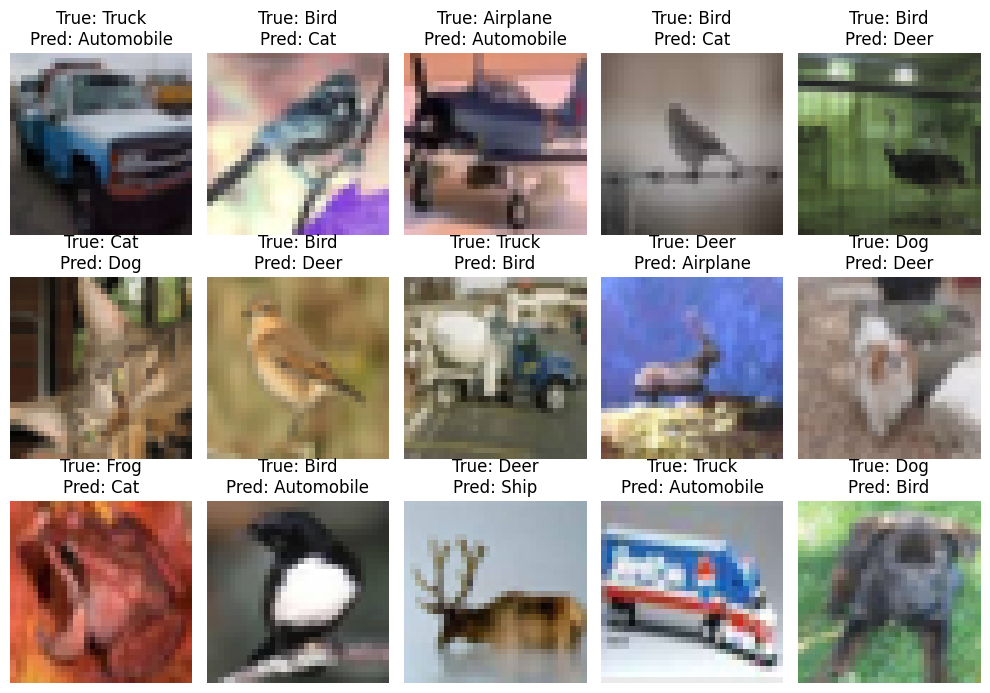

In [54]:
classes_name = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

n = min(15, len(wrong))
random_wrong = np.random.choice(wrong, size=n, replace=False)

plt.figure(figsize=(10, 7))

for i, idx in enumerate(random_wrong):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_test[idx])

    true_label = classes_name[int(y_test.argmax(axis=1)[idx])]
    pred_label = classes_name[int(yhat_classes[idx])]

    plt.title(f"True: {true_label}\nPred: {pred_label}")
    plt.axis('off')

plt.tight_layout()
plt.show()


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-radius:18px;
border-left: 8px solid #00E5FF;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">
<h2 style="color:#00E5FF;">Hyperparameter Tuning and trainig final model</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">
<ul>
<li></li>
</ul>
</div>

<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-radius:18px;
padding:35px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
text-align:center;
">

<h1 style="margin-bottom:10px;color:#00E5FF;">🎉 Thank You for rewied</h1>
<hr style="border:1px solid #8A2BE2;opacity:.4;width:70%;margin:auto;">

<br>

<h3 style="color:#E0E0E0;">Thank you for taking the time to explore this notebook.</h3>
<h5 style="font-size:17px;line-height:1.8;color:#CFCFCF;margin-top:20px;">
I hope this project has been useful and informative.<br>
Your feedback and suggestions are always appreciated.</h5>

<br>

<h2 style="color:#00E5FF;">Code • Learn • Build</h2>
</div>